### Importing libraries

In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from adjustText import adjust_text
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
)
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

### Importing data

In [2]:
economy_indicators = pd.read_csv(
    "../data/items_data_processed/league_economic_indicators.csv",
    sep=";",
    low_memory=False,
)

# PCA analysis

### 1. Filtering non-numerical data

In [3]:
pca_indicators = economy_indicators.drop(columns=["League"])

### 2. Data standarisation

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_indicators)

### 3. Applying PCA function

In [5]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

### 4. Explained variance of the principal components

Text(0, 0.5, 'Explained variance')

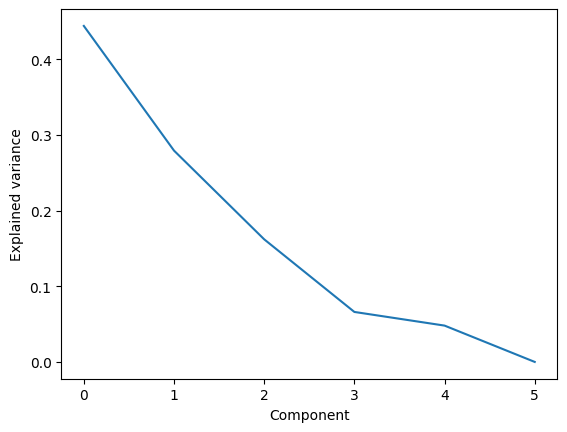

In [6]:
explained_variance = pca.explained_variance_ratio_

plt.plot(explained_variance)
plt.xlabel("Component")
plt.ylabel("Explained variance")

In [7]:
np.cumsum(pca.explained_variance_ratio_)

array([0.4443077 , 0.72375323, 0.88587406, 0.95196457, 1.        ,
       1.        ])

The explained variance plot shows how much of the total variability in the dataset is captured by each principal component obtained through Principal Component Analysis. The first principal component (PC1) explains approximately 44.4% of the total variance, while the second principal component (PC2) accounts for about 27.9%. Together, the first two components explain approximately 72.4% of the variance, indicating that a large portion of the information in the dataset can be represented in a two-dimensional space.

Including the third component increases the cumulative explained variance to about 88.6%, which means that the first three components capture the majority of the variability present in the original variables. The fourth component raises the cumulative variance to around 95.2%, after which additional components contribute only marginally.

Overall, this result suggests that most of the structural information in the dataset can be effectively summarized using the first two or three principal components, allowing for meaningful dimensionality reduction while preserving most of the original data variability.

In [8]:
# Indicators contributions to the principal components
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i + 1}" for i in range(pca.components_.shape[0])],
    index=pca_indicators.columns,
)

print(loadings)

                              PC1       PC2       PC3       PC4       PC5  \
avg_price                0.249452  0.413103 -0.090646  0.577571  0.507990   
median_price             0.097807  0.527422  0.321104 -0.433072 -0.017644   
unique_items            -0.342337 -0.307310  0.238015  0.586079 -0.126149   
total_market_value       0.417005  0.158432  0.329597  0.258186 -0.316679   
avg_daily_listings      -0.351164  0.260493  0.434248  0.044336  0.372281   
top_value_share          0.414734 -0.003287 -0.445793  0.027167  0.224361   
mean_daily_players      -0.329320  0.459125 -0.093746  0.107243 -0.195412   
listings_per_player      0.207516 -0.391108  0.465319 -0.175322  0.501860   
market_value_per_player  0.436216 -0.001619  0.332833  0.154176 -0.382695   

                              PC6  
avg_price               -0.125810  
median_price            -0.450574  
unique_items            -0.382736  
total_market_value       0.628516  
avg_daily_listings       0.163327  
top_value_sha

The loading matrix indicates that the first principal component (PC1) is mainly associated with variables related to overall market value and value concentration, including total market value, market value per player, and top value share. This suggests that PC1 represents the overall economic scale and concentration of value within the market.

The second principal component (PC2) is primarily influenced by pricing variables and player activity, such as median price, average price, and the number of daily players. This component therefore reflects market pricing dynamics and participation levels.

The third principal component (PC3) is dominated by trading-related variables, including average daily listings and listings per player, indicating that it captures the intensity of market trading and liquidity.

### 5. PCA plot

In [9]:
pca_df = pd.DataFrame(X_pca[:, :2], columns=["PC1", "PC2"])
pca_df["League"] = economy_indicators["League"]

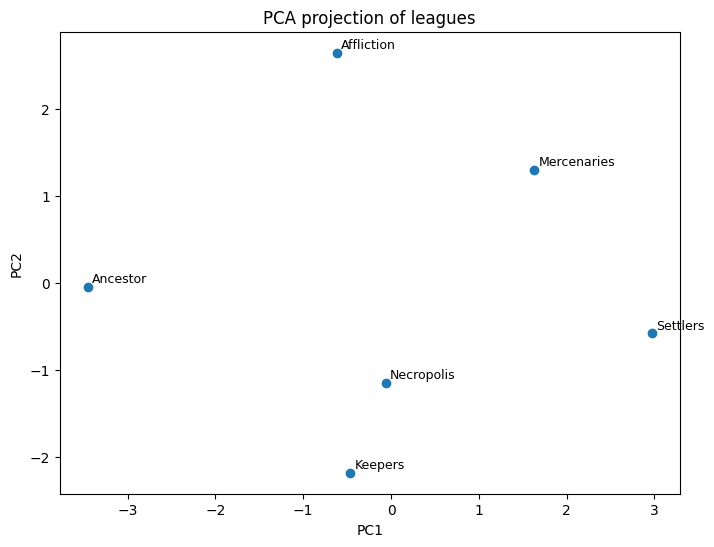

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(pca_df["PC1"], pca_df["PC2"])

# for leagues names
for i, league in enumerate(pca_df["League"]):
    plt.text(pca_df["PC1"][i] + 0.05, pca_df["PC2"][i] + 0.05, league, fontsize=9)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA projection of leagues")
plt.show()

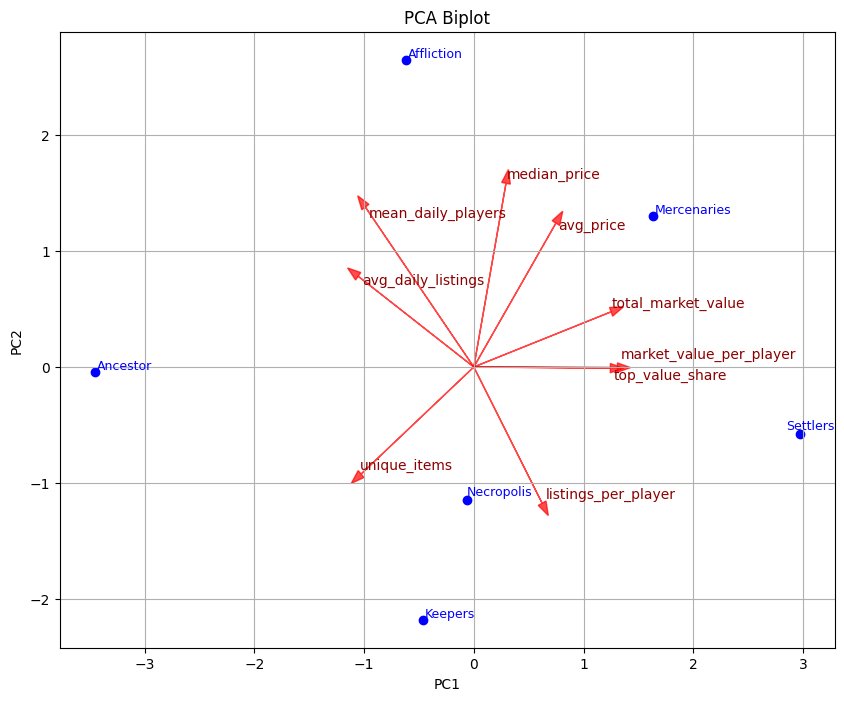

In [11]:
plt.figure(figsize=(10, 8))

texts = []

plt.scatter(pca_df["PC1"], pca_df["PC2"], color="blue")

# for leagues names
for i, league in enumerate(pca_df["League"]):
    texts.append(
        plt.text(pca_df["PC1"][i], pca_df["PC2"][i], league, fontsize=9, color="blue")
    )

# for arrows
scale = 3

for i, feature in enumerate(pca_indicators.columns):
    x = pca.components_[0, i] * scale
    y = pca.components_[1, i] * scale

    plt.arrow(0, 0, x, y, color="red", alpha=0.7, head_width=0.08)
    texts.append(plt.text(x, y, feature, color="darkred"))

# labels adjustment
adjust_text(texts)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Biplot")
plt.grid()
plt.show()

The PCA biplot illustrates the relationships between the analysed market indicators and the observed leagues in the reduced two-dimensional space. The first principal component (PC1) is primarily associated with variables describing market value and price intensity, such as total market value, market value per player, and average item price. This suggests that PC1 represents the overall economic scale of the market.

The second principal component (PC2) is mainly driven by indicators related to player participation and market activity, including the number of daily players and the number of daily listings. Therefore, PC2 reflects the level of trading activity within the market.

The distribution of leagues in the PCA space indicates clear differences in their economic structure, with some leagues characterised by higher market value and price levels, while others are associated with higher trading activity or lower market concentration.

# Clustering

## >> K-Means

### 1. Defining X variable

Clustering was performed using the first three principal components (PC1, PC2, and PC3). These components together explain approximately 89 % of the total variance in the dataset, meaning they retain most of the information contained in the original variables. Using the first three components reduces dimensionality while preserving the main structure of the data, making the clustering results more stable and interpretable.

In [12]:
X = X_pca[:, :3]  # PC1, PC2, PC3

### 2. Selection of the number of clusters

Best k (Calinski-Harabasz): 5
Best k (Silhouette): 4


<Axes: xlabel='k'>

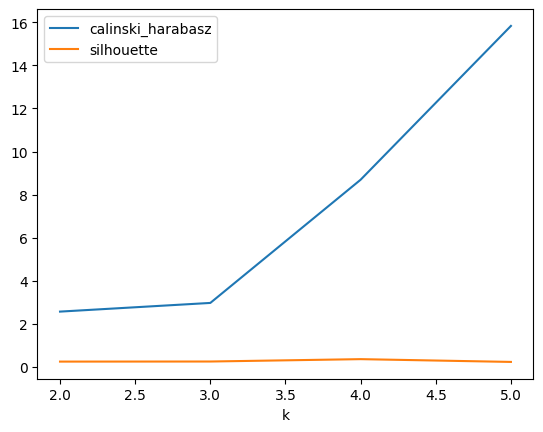

In [13]:
scores = []

for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(X)

    ch = calinski_harabasz_score(X, km.labels_)
    sil = silhouette_score(X, km.labels_)

    scores.append({"k": k, "calinski_harabasz": ch, "silhouette": sil})

res_df = pd.DataFrame(scores)

best_ch_k = res_df.loc[res_df["calinski_harabasz"].idxmax(), "k"]
best_sil_k = res_df.loc[res_df["silhouette"].idxmax(), "k"]

print(f"Best k (Calinski-Harabasz): {best_ch_k}")
print(f"Best k (Silhouette): {best_sil_k}")

res_df.plot(x="k", y=["calinski_harabasz", "silhouette"])

The optimal number of clusters was determined using the Calinski–Harabasz and Silhouette scores. While the Calinski–Harabasz index increased with the number of clusters, the Silhouette score reached its maximum for k = 4, indicating that this value provides the best balance between cluster separation and cohesion.

### 3. Influence of n_init hyperparameter

<Axes: xlabel='n_init'>

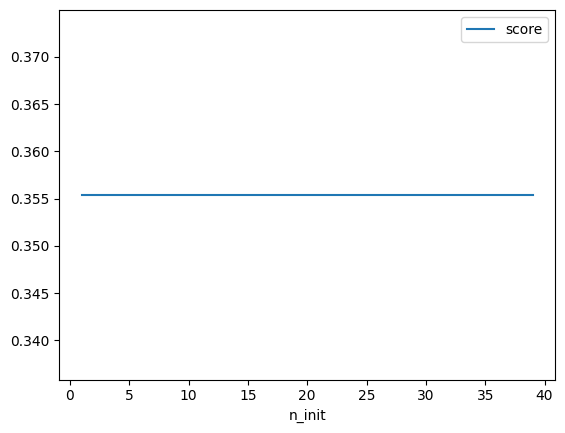

In [14]:
scores = []
for i in range(1, 40):
    kmeans = KMeans(n_clusters=4, random_state=100, n_init=i).fit(X)
    score = silhouette_score(X, kmeans.labels_)
    scores.append({"n_init": i, "score": score})
pd.DataFrame(scores).plot(x="n_init", y="score")

Because the n_init hyperparameter gives stable results, it indicates that the algorithm consistently converges to the same solution and that the data has a stable cluster structure. Since n_init does not significantly affect the outcome, the standard value n_init = 10 was used.

### 4. Influence of n_clusters hyperparameter

<Axes: xlabel='n_clusters'>

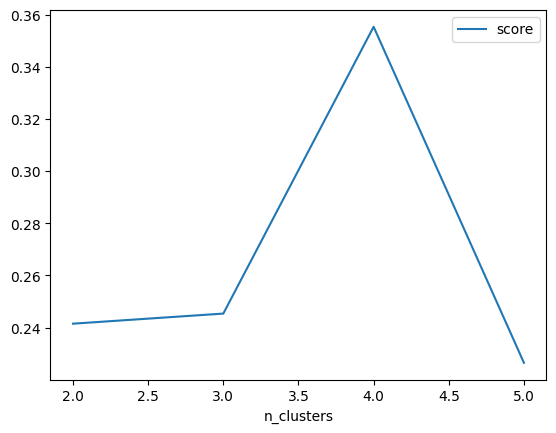

In [15]:
scores = []
for i in range(2, 6):
    kmeans = KMeans(n_clusters=i, random_state=0, n_init=10).fit(X)
    score = silhouette_score(X, kmeans.labels_)
    scores.append({"n_clusters": i, "score": score})
pd.DataFrame(scores).plot(x="n_clusters", y="score")

### 5. Clustering

In [16]:
X_cluster = X_pca[:, :3]

kmeans = KMeans(n_clusters=4, random_state=50)
clusters = kmeans.fit_predict(X_cluster)

pca_df["cluster"] = clusters

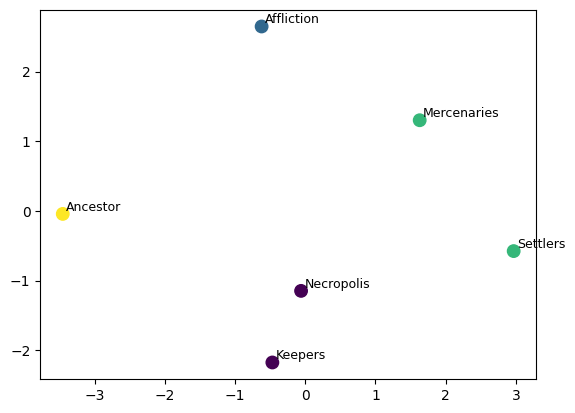

In [17]:
plt.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["cluster"], cmap="viridis", s=80)

# for leagues names
for i, league in enumerate(pca_df["League"]):
    plt.text(pca_df["PC1"][i] + 0.05, pca_df["PC2"][i] + 0.05, league, fontsize=9)

## >> Hierarchical clustering

### 1. Clustering

In [18]:
agg = AgglomerativeClustering(n_clusters=4)
clusters = agg.fit_predict(X_cluster)

pca_df["agg_cluster"] = clusters

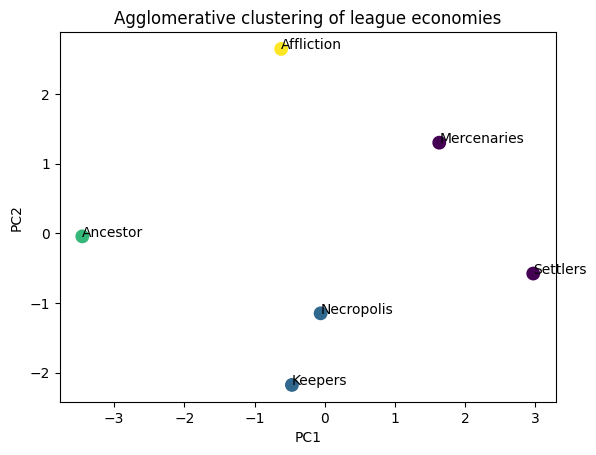

In [19]:
plt.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["agg_cluster"], cmap="viridis", s=80)

for i in range(len(pca_df)):
    plt.text(pca_df["PC1"][i], pca_df["PC2"][i], pca_df["League"][i])

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Agglomerative clustering of league economies")
plt.show()

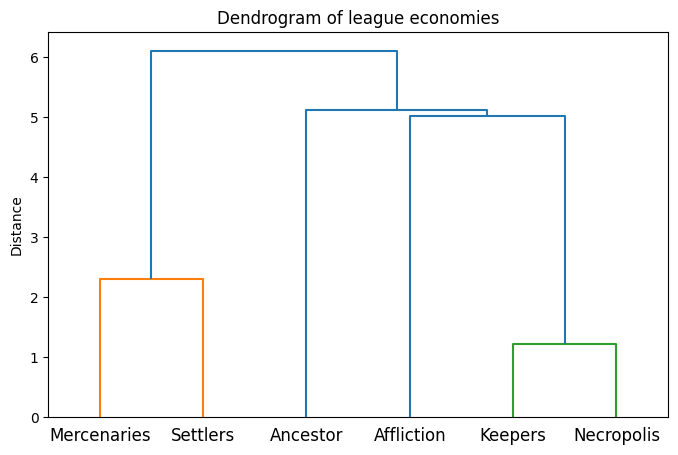

In [20]:
linked = linkage(X_cluster, method="ward")

plt.figure(figsize=(8, 5))
dendrogram(linked, labels=pca_df["League"].values)
plt.title("Dendrogram of league economies")
plt.ylabel("Distance")
plt.show()

### 2. Linkage and number of clusters selection

In [21]:
linkages = ["ward", "complete", "average", "single"]
results = []

for link in linkages:
    for k in range(2, 6):  # masz 6 lig więc 2–5 wystarczy
        if link == "ward":
            model = AgglomerativeClustering(n_clusters=k, linkage="ward")
        else:
            model = AgglomerativeClustering(
                n_clusters=k, linkage=link, metric="euclidean"
            )

        labels = model.fit_predict(X_cluster)

        if len(set(labels)) > 1:
            sil = silhouette_score(X_cluster, labels)
            ch = calinski_harabasz_score(X_cluster, labels)
            db = davies_bouldin_score(X_cluster, labels)
        else:
            sil, ch, db = float("nan"), float("nan"), float("nan")

        results.append(
            {
                "linkage": link,
                "k": k,
                "silhouette": sil,
                "calinski_harabasz": ch,
                "davies_bouldin": db,
            }
        )

hc_df = pd.DataFrame(results)

display(hc_df.sort_values("silhouette", ascending=False).head(10))

,linkage,k,silhouette,calinski_harabasz,davies_bouldin
2,ward,4,0.355407,8.690459,0.348928
6,complete,4,0.355407,8.690459,0.348928
14,single,4,0.355407,8.690459,0.348928
10,average,4,0.355407,8.690459,0.348928
1,ward,3,0.245370,2.966881,0.766006
0,ward,2,0.241496,2.563821,0.971771
8,average,2,0.228896,2.338704,0.517447
12,single,2,0.228896,2.338704,0.517447
15,single,5,0.226492,15.834477,0.148414
11,average,5,0.226492,15.834477,0.148414


<Axes: title={'center': 'Davies-Bouldin vs linkage'}, xlabel='k'>

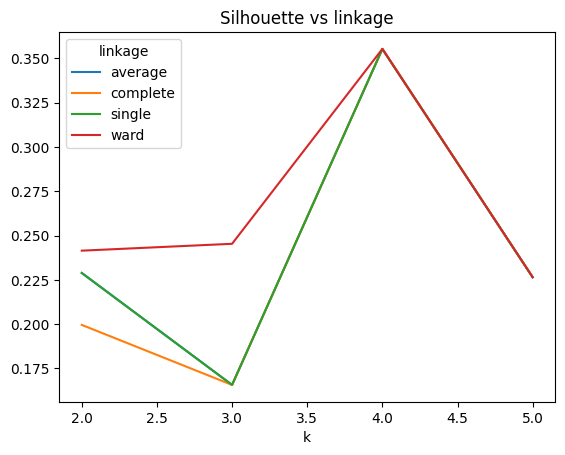

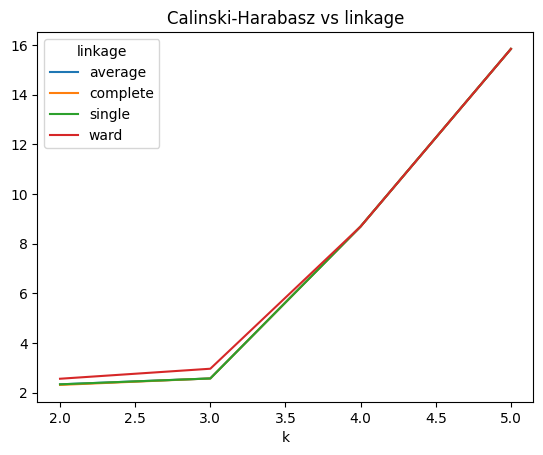

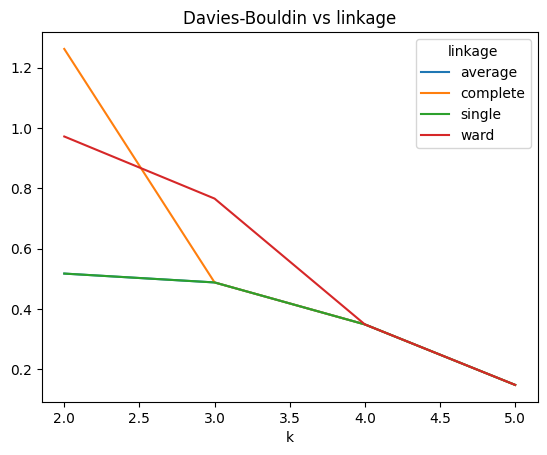

In [22]:
hc_df.pivot(index="k", columns="linkage", values="silhouette").plot(
    title="Silhouette vs linkage"
)
hc_df.pivot(index="k", columns="linkage", values="calinski_harabasz").plot(
    title="Calinski-Harabasz vs linkage"
)
hc_df.pivot(index="k", columns="linkage", values="davies_bouldin").plot(
    title="Davies-Bouldin vs linkage"
)

The evaluation metrics indicate that **k = 4 or k = 5** provides the best clustering structure. As all linkage methods produced the same results, **ward linkage** was selected for the final hierarchical clustering model. 


In [23]:
agg = AgglomerativeClustering(n_clusters=5)
clusters = agg.fit_predict(X_cluster)

pca_df["agg_cluster"] = clusters

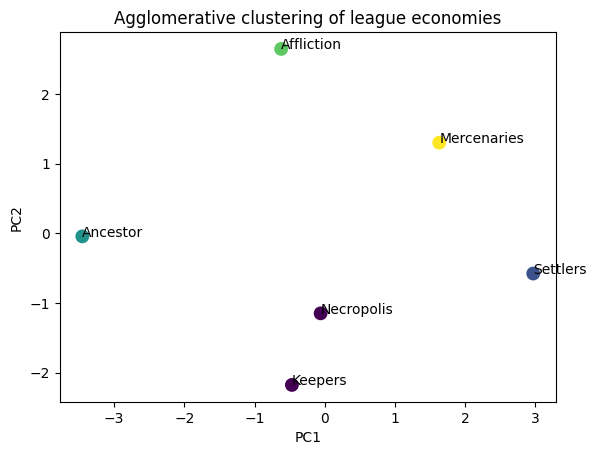

In [24]:
plt.scatter(pca_df["PC1"], pca_df["PC2"], c=pca_df["agg_cluster"], cmap="viridis", s=80)

for i in range(len(pca_df)):
    plt.text(pca_df["PC1"][i], pca_df["PC2"][i], pca_df["League"][i])

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Agglomerative clustering of league economies")
plt.show()

The difference between k = 4 and k = 5 arises mainly from the relationship between the Mercenaries and Settlers leagues. These two points are relatively close to each other, but this proximity is not that clear. Consequently, they can either form a single cluster (k = 4) or two separate clusters (k = 5).

**Conclusions:**

1. The PCA analysis reveals clear structural differences between league economies. The first principal component is mainly associated with market value indicators such as total market value, market value per player, and top value share, while the second component is more related to player activity and itmes listing dynamics. This indicates that league economies differ primarily in terms of overall market value and trading activity.

2. The clustering analysis identifies four distinct types of league economies, and both K-means and hierarchical clustering produce the same grouping, suggesting that the cluster structure is stable and reliable across different clustering methods.

3. The **Settlers and Mercenaries** leagues form one cluster characterised by high market value and relatively high prices, indicating larger and more valuable economies where expensive items play an important role in the market structure.

4. The **Keepers and Necropolis** leagues form another cluster characterised by higher itmes listing activity and item diversity, but lower overall market value. These leagues appear to have active markets with many items traded, although the average value of transactions is lower.

5. The **Affliction** league forms a separate cluster and is primarily associated with high player activity and a large number of daily listings, suggesting that its economy is driven mainly by population size and intense market participation.

6. The **Ancestor** league also forms its own cluster and appears economically distinct from the others. Its position in the PCA space indicates lower market value and weaker concentration of expensive items, suggesting a smaller or less value-concentrated economy.

The consistency between PCA visualisation and clustering results indicates that the observed differences between league economies are systematic rather than random, reflecting stable structural characteristics of each league market.